# Pregunta 1: Salto de un cuadrúpedo sobre un obstáculo

| Kamt, L., Reyes, K.

El **Unitree Go2** tiene enfrente un obstáculo alto (una caja de 0.25 m) que no puede atravesar caminando. Se presenta el salto mediante optimización de trayectorias. Todos los parámetros del robot se leen del URDF en módulo `go2_modelo.py`.

In [35]:
import os
import time
import numpy as np
import casadi as ca
import matplotlib.pyplot as plt
import go2_modelo as go2

from matplotlib.animation import FuncAnimation, PillowWriter
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.integrate import solve_ivp
from IPython.display import Image, display

In [36]:
FIG = "figuras"
os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

## 1.1.- Parámetros del Go2

El programa `go2_modelo.py` es el que lee el URDF y obtiene masas, centros de masa, tensores de inercia, orígenes de las articulaciones, límites articulares y de torque, y la caja de colisión del tronco.

In [37]:
go2.resumen()

Masa total [kg]                               15.019
Masa del tronco [kg]                          6.921
Masa por pata (hip/thigh/calf/foot) [kg]      0.678/1.152/0.154/0.04
Cadera (abducción) en {B} [m]                 (±0.1934, ±0.0465, 0)
Offset lateral del muslo L0 [m]               0.0955
Muslo L1 / pierna L2 [m]                      0.213 / 0.213
Caja del tronco [m]                           [0.3762 0.0935 0.114 ]
q_min [rad]                                   [-1.0472 -1.5708 -2.7227]
q_max [rad]                                   [ 1.0472   3.4907  -0.83776]
Torque máx. [N m]                             [23.7  23.7  45.43]
Velocidad máx. [rad/s]                        [30.1 30.1 15.7]


In [38]:
m = go2.MASA
g = go2.G
I_b, cdm_b = go2.inercia_srbm()
print(f"Masa total m = {m:.3f} kg")
print("Inercia del SRBM respecto del CdM [kg m^2]:\n", np.round(I_b, 4))

Masa total m = 15.019 kg
Inercia del SRBM respecto del CdM [kg m^2]:
 [[ 0.1836  0.     -0.0046]
 [ 0.      0.4473 -0.    ]
 [-0.0046 -0.      0.5259]]


## 1.2.- Secuencia de contactos de las patas

* El robot parte en reposo con el CdM en $\mathbf p_0=(0,0,0.30)$ m y debe terminar en reposo, en postura nominal, en $\mathbf p_f=(1.20,0,0.30)$ m.
* El obstáculo es una caja de altura $H=0.25$ m entre $x_1=0.42$ y $x_2=0.67$ m.
* Fricción $\mu=0.7$
* Fuerza normal máxima por pata 220 N.
* Rango de duración total de la fase j: $T_j$
* Número de intervalos de discretización de la fase j: $N_j$

| Fase | Descripción | Pies en contacto | $N_j$ | $T_j$ [s] |
|---|---|---|---|---|
| 1 | Impulso con 4 patas | FR, FL, RR, RL | 22 | [0.25, 0.80] |
| 2 | Impulso con traseras | RR, RL | 10 | [0.05, 0.15] |
| 3 | Vuelo | - | 24 | [0.15, 1.70] |
| 4 | Aterrizaje delanteras | FR, FL | 10 | [0.05, 0.15] |

In [39]:
mu      = 0.7                  # coeficiente de fricción
f_max   = 220.0                # fuerza normal máxima por pata [N]
z0      = 0.30                 # altura nominal del CdM [m]
x_final = 1.20                 # posición final del CdM, más allá del obstáculo

# Pies en postura nominal {B}: bajo cada articulación de cadera
P_PIE_NOM = go2.P_CADERA.copy()
P_PIE_NOM[:, 2] = -z0

# Obstáculo: caja de altura H entre x1 y x2, en y ocupa todo el ancho del robot
OBS_X1  = 0.42
OBS_X2  = 0.67
OBS_H   = 0.25
MARGEN  = 0.03                  # margen de seguridad para la restricción
k_suave = 80.0                  # pendiente de la aproximación suave del obstáculo

# Secuencia de contactos. Orden: FR, FL, RR, RL
FASES = [
    dict(nombre="1", contacto=[1, 1, 1, 1], N=22, T=(0.25, 0.80), T0=0.45),
    dict(nombre="2", contacto=[0, 0, 1, 1], N=10, T=(0.05, 0.15), T0=0.12),
    dict(nombre="3", contacto=[0, 0, 0, 0], N=24, T=(0.15, 1.70), T0=0.40),
    dict(nombre="4", contacto=[1, 1, 0, 0], N=10, T=(0.05, 0.15), T0=0.12),
    dict(nombre="5", contacto=[1, 1, 1, 1], N=22, T=(0.25, 0.80), T0=0.50),
]
NF = len(FASES)

# Conjunto de pies que usa cada pata en cada fase
APOYO_ID = [[0, 0, 0, 0], 
            [0, 0, 0, 0], 
            [0, 0, 0, 0], 
            [1, 1, 0, 0], 
            [1, 1, 1, 1]]
# Ventanas de extensión de las patas antes del aterrizaje: {fase: (patas, fracción de inicio)}
#   delanteras: último 40 % del vuelo;  traseras: toda la fase de aterrizaje delantero
VENTANA_EXT = {2: ([0, 1], 0.6), 3: ([2, 3], 0.0)}
FRAC_REC = 0.4                 # las traseras se recogen durante el primer 40 % del vuelo

## 1.3.- Modelo dinámico: SRBM

Estado y entrada:
$$
\mathbf x=\begin{bmatrix}\mathbf p^\top & \boldsymbol\eta^\top & \mathbf v^\top & {}^b\boldsymbol\omega^\top\end{bmatrix}^\top\in\mathbb R^{12},
\qquad
\mathbf u=\begin{bmatrix}\mathbf f_{FR}^\top & \mathbf f_{FL}^\top & \mathbf f_{RR}^\top & \mathbf f_{RL}^\top\end{bmatrix}^\top\in\mathbb R^{12},
$$
con $\boldsymbol\eta=(\phi,\theta,\psi)$ los ángulos roll-pitch-yaw y $\mathbf f_i$ la fuerza del suelo sobre el pie $i$ ubicado en $\mathbf p_i$. La dinámica es
$$
\dot{\mathbf p}=\mathbf v,\qquad
\dot{\mathbf v}=\mathbf g+\frac1m\sum_{i=1}^4\mathbf f_i,\qquad
\dot{\boldsymbol\eta}=E(\phi,\theta)\,{}^b\boldsymbol\omega,\qquad
I\,{}^b\dot{\boldsymbol\omega}={}^wR_b^\top\sum_{i=1}^4(\mathbf p_i-\mathbf p)\times\mathbf f_i-{}^b\boldsymbol\omega\times(I\,{}^b\boldsymbol\omega),
$$
donde $E(\phi,\theta)$ relaciona la velocidad angular del cuerpo con las derivadas de los ángulos de Euler.

In [ ]:
xs = ca.SX.sym("x", 12)
us = ca.SX.sym("u", 12)
pf = ca.SX.sym("pf", 12)                          # posiciones de los 4 pies en {W}

phi, th, psi = xs[3], xs[4], xs[5]
Rx = ca.vertcat(ca.horzcat(1, 0, 0), ca.horzcat(0, ca.cos(phi), -ca.sin(phi)),
                ca.horzcat(0, ca.sin(phi), ca.cos(phi)))
Ry = ca.vertcat(ca.horzcat(ca.cos(th), 0, ca.sin(th)), ca.horzcat(0, 1, 0),
                ca.horzcat(-ca.sin(th), 0, ca.cos(th)))
Rz = ca.vertcat(ca.horzcat(ca.cos(psi), -ca.sin(psi), 0),
                ca.horzcat(ca.sin(psi), ca.cos(psi), 0), ca.horzcat(0, 0, 1))
R = Rz @ Ry @ Rx                                   # {B} -> {W}
R_fun = ca.Function("R", [xs], [R])

w = xs[9:12]
E = ca.vertcat(ca.horzcat(1, ca.sin(phi) * ca.tan(th), ca.cos(phi) * ca.tan(th)),
               ca.horzcat(0, ca.cos(phi), -ca.sin(phi)),
               ca.horzcat(0, ca.sin(phi) / ca.cos(th), ca.cos(phi) / ca.cos(th)))

# >> Fuerza total y momento total en {W} de las fuerzas de contacto
f_tot = ca.SX.zeros(3)
tau_w = ca.SX.zeros(3)
for i in range(4):
    fi = us[3 * i:3 * i + 3]
    ri = pf[3 * i:3 * i + 3] - xs[0:3]
    f_tot += fi
    tau_w += ca.cross(ri, fi)

p_dot = xs[6:9]
eta_dot = E @ w
v_dot = f_tot / m - ca.DM([0, 0, g])
Ib = ca.DM(I_b)
w_dot = ca.solve(Ib, R.T @ tau_w - ca.cross(w, Ib @ w))
f_din = ca.Function("f_srbm", [xs, us, pf], [ca.vertcat(p_dot, eta_dot, v_dot, w_dot)])

**Integrador RK4**

In [41]:
hs = ca.SX.sym("h")
xk = xs
for _ in range(2):
    d = hs / 2
    k1 = f_din(xk, us, pf)
    k2 = f_din(xk + d / 2 * k1, us, pf)
    k3 = f_din(xk + d / 2 * k2, us, pf)
    k4 = f_din(xk + d * k3, us, pf)
    xk = xk + d / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
Phi = ca.Function("Phi_RK4", [xs, us, pf, hs], [xk])

## 1.4.- Restricciones

Para que la restricción sea diferenciable, la caja se representa mediante el producto de dos sigmoides, inflado por un margen $\delta=3$ cm:
$$
h_{\rm obs}(x)=(H+\delta)\,\sigma\big(k(x-x_1+\delta)\big)\,\sigma\big(k(x_2+\delta-x)\big),\qquad \sigma(s)=\frac{1}{1+e^{-s}},\ k=80 .
$$
Cada punto del robot debe cumplir $z\ge h_{\rm obs}(x)$.

**Cinemática inversa en plano sagital.** Si bien las patas del SRBM no tienen masa, su geometría importa. La rodilla del Go2 apunta hacia atrás y puede chocar con el obstáculo. Para un pie en $\mathbf d=(d_x,d_y,d_z)$ relativo a la cadera:
$$
q_2=-\arccos\frac{d_x^2+d_z^2-L_1^2-L_2^2}{2L_1L_2},\qquad
q_1=\operatorname{atan2}(-d_x,-d_z)-\operatorname{atan2}(L_2\sin q_2,\ L_1+L_2\cos q_2),
$$
y la rodilla está en $(-L_1\sin q_1,\ 0,\ -L_1\cos q_1)$ respecto de la cadera. Estas expresiones se usan dentro del NLP.

Pose recogida: q1 = 73.6°, q2 = -147.3°; rodilla relativa a la cadera = [-0.204  0.    -0.06 ]


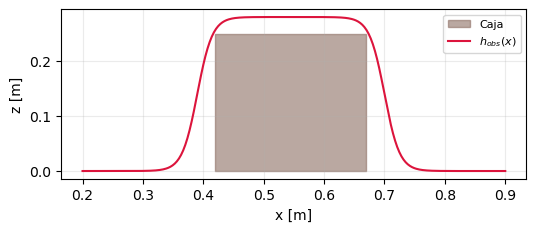

In [42]:
def ci_sagital(d):
    """CI simbólica: ángulos (cadera, rodilla) para el pie d relativo a la cadera (en {B})."""
    dx, dz = d[0], d[2]
    c2 = (dx**2 + dz**2 - go2.L1**2 - go2.L2**2) / (2 * go2.L1 * go2.L2)
    q2 = -ca.acos(ca.fmax(ca.fmin(c2, 0.999), -0.999))   # saturación (sólo actúa en la estimación inicial)
    q1 = ca.atan2(-dx, -dz) - ca.atan2(go2.L2 * ca.sin(q2), go2.L1 + go2.L2 * ca.cos(q2))
    return q1, q2


def cd_sagital(q1, q2):
    """CD sagital: rodilla y pie relativos a la cadera (en {B})."""
    rod = ca.vertcat(-go2.L1 * ca.sin(q1), 0, -go2.L1 * ca.cos(q1))
    pie = rod + ca.vertcat(-go2.L2 * ca.sin(q1 + q2), 0, -go2.L2 * ca.cos(q1 + q2))
    return rod, pie


def rodilla_ci(d):
    return cd_sagital(*ci_sagital(d))[0]


def altura_obstaculo(x, lib=ca):
    """Perfil suave del obstáculo (producto de dos sigmoides), inflado por MARGEN."""
    s1 = 1 / (1 + lib.exp(-k_suave * (x - (OBS_X1 - MARGEN))))
    s2 = 1 / (1 + lib.exp(-k_suave * ((OBS_X2 + MARGEN) - x)))
    return (OBS_H + MARGEN) * s1 * s2


# Puntos que deben pasar sobre el obstáculo (marco {B})
lx, ly, lz = go2.CUERPO / 2
ESQ_INF = np.array([[sx * lx, sy * ly, -lz] for sx in (1, -1) for sy in (1, -1)])   # esquinas del tronco
PIE_RECOGIDO = P_PIE_NOM.copy()
PIE_RECOGIDO[:, 2] = -0.12                                                          # pie de la pata recogida en vuelo
Q_REC = [float(v) for v in ci_sagital(ca.DM([0, 0, -0.12]))]                        # pose recogida (cadera, rodilla)
RODILLA_RECOGIDA = go2.P_CADERA + np.array(cd_sagital(*Q_REC)[0]).ravel()
print(f"Pose recogida: q1 = {np.degrees(Q_REC[0]):.1f}°, q2 = {np.degrees(Q_REC[1]):.1f}°;"
      f" rodilla relativa a la cadera = {np.round(RODILLA_RECOGIDA[0] - go2.P_CADERA[0], 3)}")

xx = np.linspace(0.2, 0.9, 400)
plt.figure(figsize=(6, 2.2))
plt.fill_between([OBS_X1, OBS_X2], 0, OBS_H, color="#8d6e63", alpha=0.6, label="Caja")
plt.plot(xx, altura_obstaculo(xx, np), color="crimson", label="$h_{obs}(x)$")
plt.xlabel("x [m]")
plt.ylabel("z [m]")
plt.legend(fontsize=8)
plt.show()

## 1.5.- Formulación del multiple shooting

### Paso 1: Malla y nodos globales

Las fases $j=1,\dots,5$ se concatenan en una sola malla con
$$
N=\sum_{j=1}^{5}N_j = 22+10+24+10+22 = 88
$$
intervalos, nodos $k=0,\dots,N$ y $\mathbf x_0=\mathbf x_{\rm ini}$ fijo. Sea $j(k)$ la fase a la que pertenece el intervalo $[t_k,t_{k+1}]$. Entonces
$$
h_k=\frac{T_{j(k)}}{N_{j(k)}},\qquad t_{k+1}=t_k+h_k .
$$
Como el último nodo de la fase $j$ es el primero de la fase $j+1$, la continuidad entre fases queda garantizada por la misma restricción de continuidad. Las fuerzas son constantes en cada intervalo.

### Paso 2: Vector de decisión

$$
\mathbf z=\big(\mathbf x_1,\dots,\mathbf x_N,\ \mathbf u_0,\dots,\mathbf u_{N-1},\ T_1,\dots,T_5,\ x^a_1,\dots,x^a_4\big)
$$
donde $x^a_i$ es la coordenada $x$ del pie $i$ al aterrizar. Las posiciones de los pies en el intervalo $k$, $\mathbf p^c_k$, son fijas en el despegue y dependen de $x^a_i$ después del aterrizaje; por eso la dinámica depende de $\mathbf z$ también a través de ellas.

### Paso 3: Integración local

Con el estado y el control del nodo $k$ se predice el estado al final del intervalo integrando el SRBM con RK4 (2 subpasos de $h_k/2$):
$$
\hat{\mathbf x}_{k+1}=\boldsymbol\Psi_k(\mathbf x_k,\mathbf u_k,h_k)\equiv\Phi^{\rm RK4}\big(\mathbf x_k,\mathbf u_k,\mathbf p^c_k,h_k\big).
$$
Un integrador distinto cambiaría $\boldsymbol\Psi_k$, pero no la estructura de la formulación.

### Paso 4: Residuo de continuidad

El estado independiente del nodo siguiente, $\mathbf x_{k+1}$, debe coincidir con el estado predicho:
$$
\mathbf d_k(\mathbf z)=\mathbf x_{k+1}-\hat{\mathbf x}_{k+1}=\mathbf x_{k+1}-\boldsymbol\Psi_k(\mathbf x_k,\mathbf u_k,h_k)=\mathbf 0,\qquad k=0,\dots,N-1
$$
Para $k=0$ se incluye la condición inicial: $\mathbf d_0(\mathbf z)=\mathbf x_1-\boldsymbol\Psi_0(\mathbf x_{\rm ini},\mathbf u_0,h_0)=\mathbf 0$. Esto da $12N$ ecuaciones, una por cada componente del estado en cada intervalo.

### Paso 5: Costo

Sin término terminal ($\Phi=0$), solo un costo de Lagrange:
$$
J(\mathbf z)=\sum_{k=0}^{N-1}h_k\,\ell_k+0.02\sum_{k=1}^{N-1}\Big\|\tfrac{\mathbf u_k-\mathbf u_{k-1}}{mg}\Big\|^2,
\qquad
\ell_k=\Big\|\tfrac{\mathbf u_k-\mathbf u^{\rm est}_k}{mg}\Big\|^2+0.05\|{}^b\boldsymbol\omega_k\|^2+2(\phi_k^2+\psi_k^2)
$$
donde $\mathbf u^{\rm est}_k$ es el peso repartido entre las patas en apoyo: se penaliza la desviación respecto del apoyo estático.

### Paso 6: Problema discretizado (NLP)

$$
\begin{aligned}
\min_{\mathbf z}\quad & J(\mathbf z)\\
\text{s.a.}\quad
& \mathbf d_k(\mathbf z)=\mathbf 0, && k=0,\dots,N-1 \quad\text{(continuidad)}\\
& \boldsymbol\psi_f(\mathbf x_N)=\mathbf x_N-\mathbf x_f=\mathbf 0 && \text{(condición final)}\\
& \mathbf c_{\rm eq}(\mathbf u_k)=\mathbf f_{i,k}=\mathbf 0,\ \ i\notin\mathcal S_{j(k)}, && k=0,\dots,N-1 \quad\text{(pie en el aire)}\\
& \mathbf c_{\rm ineq}(\mathbf x_k,\mathbf u_k)\le \mathbf 0, && k=0,\dots,N-1\\
& \mathbf x_{\min}\le\mathbf x_k\le\mathbf x_{\max}, && k=1,\dots,N\\
& T_j^{\min}\le T_j\le T_j^{\max}, && j=1,\dots,5
\end{aligned}
$$
No hay restricciones en instantes intermedios ($n_{\rm int}=0$): las transiciones de fase coinciden con nodos de la malla. Aquí $\mathcal S_{j}$ es el conjunto de patas en apoyo en la fase $j$.

**Contenido de $\mathbf c_{\rm ineq}\le\mathbf 0$** 
$$
\begin{aligned}
& 0\le f_{z,i}\le f_{\max},\quad |f_{x,i}|\le\mu f_{z,i},\quad |f_{y,i}|\le\mu f_{z,i} && \text{(pie en apoyo)}\\
& 0.20\le\|\mathbf d_i\|\le0.39,\quad |d_{i,x}|\le0.20,\quad \mathbf d_i={}^wR_b^\top(\mathbf p^c_i-\mathbf p)-\mathbf r^{cad}_i && \text{(alcance de la pata)}\\
& z\ge h_{\rm obs}(x)\ && \text{(para cada punto } c=(x_c,y_c,z_c) \text{ del robot)}\\
\end{aligned}
$$

**Cotas de estado:** $|\phi|\le0.3$ y $|\theta|\le0.8$. Las restricciones geométricas y de orientación se evalúan en los nodos $\mathbf x_k$ y en el punto medio $\mathbf x_{k+1/2}=\boldsymbol\Psi_k(\mathbf x_k,\mathbf u_k,h_k/2)$ de cada intervalo.

In [ ]:
opti = ca.Opti()
T_fase = opti.variable(NF)
x_ini = np.r_[0, 0, z0, np.zeros(9)]
x_fin = np.r_[x_final, 0, z0, np.zeros(9)]

# >> Pies de despegue (fijos) y de aterrizaje (x libre, z = 0)
pies_despegue = P_PIE_NOM.copy(); pies_despegue[:, 2] = 0.0
x_aterr = opti.variable(4)
pies_aterr = [ca.vertcat(x_aterr[i], P_PIE_NOM[i, 1], 0) for i in range(4)]

X_fases, U_fases = [], []
J = 0
x_prev = ca.DM(x_ini)
for f_id, fase in enumerate(FASES):
    N = fase["N"]
    h = T_fase[f_id] / N
    X = opti.variable(12, N)
    U = opti.variable(12, N)
    Xc = ca.horzcat(x_prev, X)           # la primera columna es el último nodo de la fase anterior
    X_fases.append(Xc); U_fases.append(U)

    # >> Posiciones de los pies (en {W}) usadas por la dinámica de esta fase
    pf_list = [ca.DM(pies_despegue[i]) if APOYO_ID[f_id][i] == 0 else pies_aterr[i] for i in range(4)]
    pf_fase = ca.vertcat(*pf_list)

    for k in range(N):
        xk_, uk_ = Xc[:, k], U[:, k]
        x_med = Phi(xk_, uk_, pf_fase, h / 2)       # punto medio (para restricciones)
        opti.subject_to(Xc[:, k + 1] == Phi(xk_, uk_, pf_fase, h))

        # >> fuerzas de contacto: unilateralidad, pirámide de fricción, nulas en vuelo
        for i in range(4):
            fi = uk_[3 * i:3 * i + 3]
            if fase["contacto"][i]:
                opti.subject_to(opti.bounded(0, fi[2], f_max))
                opti.subject_to(opti.bounded(-mu * fi[2], fi[0], mu * fi[2]))
                opti.subject_to(opti.bounded(-mu * fi[2], fi[1], mu * fi[2]))
            else:
                opti.subject_to(fi == 0)

        # >> restricciones geométricas en el nodo y en el punto medio
        for xe in ([xk_, x_med] if (k > 0 or f_id > 0) else [x_med]):
            Re = R_fun(xe)
            pe = xe[0:3]
            # esquinas inferiores del tronco por encima del suelo y del obstáculo
            for c in ESQ_INF:
                pc = pe + Re @ ca.DM(c)
                opti.subject_to(pc[2] >= altura_obstaculo(pc[0]))
                opti.subject_to(pc[2] >= 0.05)
            # >> patas en el aire (recogidas): pie y rodilla por encima del obstáculo
            for i in range(4):
                if not fase["contacto"][i]:
                    for punto in (PIE_RECOGIDO[i], RODILLA_RECOGIDA[i]):
                        pc = pe + Re @ ca.DM(punto)
                        opti.subject_to(pc[2] >= altura_obstaculo(pc[0]))
            # >> ventana de extensión: todo el barrido recogida -> aterrizaje libra el obstáculo
            if f_id in VENTANA_EXT and k >= VENTANA_EXT[f_id][1] * N:
                x_td = Xc[:, -1]                          # estado en el instante de contacto
                for i in VENTANA_EXT[f_id][0]:
                    d_td = R_fun(x_td).T @ (pies_aterr[i] - x_td[0:3]) - ca.DM(go2.P_CADERA[i])
                    q1_td, q2_td = ci_sagital(d_td)
                    for sb in (0.25, 0.5, 0.75, 1.0):
                        rod, pie = cd_sagital((1 - sb) * Q_REC[0] + sb * q1_td,
                                              (1 - sb) * Q_REC[1] + sb * q2_td)
                        for punto in (rod, pie):
                            pc = pe + Re @ (ca.DM(go2.P_CADERA[i]) + punto)
                            opti.subject_to(pc[2] >= altura_obstaculo(pc[0]))
            # >> patas en apoyo: alcance cinemático y rodilla (CI simbólica) libre
            for i in range(4):
                if fase["contacto"][i]:
                    d = Re.T @ (pf_list[i] - pe) - ca.DM(go2.P_CADERA[i])   # en {B}
                    opti.subject_to(ca.sumsqr(d) <= 0.39**2)
                    opti.subject_to(ca.sumsqr(d) >= 0.20**2)
                    opti.subject_to(opti.bounded(-0.20, d[0], 0.20))
                    pr = pe + Re @ (ca.DM(go2.P_CADERA[i]) + rodilla_ci(d))
                    opti.subject_to(pr[2] >= altura_obstaculo(pr[0]))
                    opti.subject_to(pr[2] >= 0.03)
            # >> orientación: sin vuelcos laterales y cabeceo moderado
            opti.subject_to(opti.bounded(-0.3, xe[3], 0.3))
            opti.subject_to(opti.bounded(-0.8, xe[4], 0.8))

        # >> costo: desviación del apoyo estático, velocidad angular y suavidad
        nc = sum(fase["contacto"])
        u_est = np.zeros(12)
        for i in range(4):
            if fase["contacto"][i]:
                u_est[3 * i + 2] = m * g / nc
        J += h * (ca.sumsqr((uk_ - u_est) / (m * g)) + 0.05 * ca.sumsqr(xk_[9:12])
                  + 2.0 * (xk_[3]**2 + xk_[5]**2))
        if k > 0:
            J += 0.02 * ca.sumsqr((uk_ - U[:, k - 1]) / (m * g))
    x_prev = Xc[:, -1]

# >> Condición final, duraciones acotadas y pies de aterrizaje
opti.subject_to(x_prev == ca.DM(x_fin))
for f_id, fase in enumerate(FASES):
    opti.subject_to(opti.bounded(fase["T"][0], T_fase[f_id], fase["T"][1]))
opti.subject_to(x_aterr >= OBS_X2 + 0.06)                     # aterrizan después del obstáculo
opti.subject_to(opti.bounded(-0.04, x_aterr - (x_final + go2.SIGNO_X * go2.HIP_X), 0.04))  # postura final nominal
opti.subject_to(x_aterr[0] == x_aterr[1])                     # simetría izquierda/derecha
opti.subject_to(x_aterr[2] == x_aterr[3])
opti.minimize(J)
print(f"Variables: {opti.nx} | restricciones: {opti.ng}")

Variables: 2121 | restricciones: 7613


## 1.6.- Solución

In [44]:
T_tot0 = sum(f["T0"] for f in FASES)
t_acum = 0.0
for f_id, fase in enumerate(FASES):
    N = fase["N"]
    opti.set_initial(T_fase[f_id], fase["T0"])
    tt = t_acum + np.linspace(0, fase["T0"], N + 1)[1:]
    s = tt / T_tot0
    x_g = np.zeros((12, N))
    x_g[0] = x_final * (10 * s**3 - 15 * s**4 + 6 * s**5)
    x_g[2] = z0 + 0.22 * np.sin(np.pi * s)**2
    x_g[6] = np.gradient(x_g[0], tt)
    opti.set_initial(X_fases[f_id][:, 1:], x_g)
    u_g = np.zeros((12, N))
    for i in range(4):
        if fase["contacto"][i]:
            u_g[3 * i + 2] = m * g / sum(fase["contacto"])
    opti.set_initial(U_fases[f_id], u_g)
    t_acum += fase["T0"]
opti.set_initial(x_aterr, [x_final + 0.19, x_final + 0.19, x_final - 0.19, x_final - 0.19])

opti.solver("ipopt", {"expand": True, "print_time": False},
            {"print_level": 0, "max_iter": 3000, "tol": 1e-6,
             "acceptable_tol": 1e-4, "mu_strategy": "adaptive"})
t0 = time.time()
sol = opti.solve()
print(f"IPOPT: {sol.stats()['return_status']} | iteraciones: {sol.stats()['iter_count']} "
      f"| tiempo: {time.time() - t0:.1f} s | costo: {sol.value(J):.4f}")

IPOPT: Solve_Succeeded | iteraciones: 50 | tiempo: 52.3 s | costo: 0.3376


## 1.7.- Recuperación de la solución

In [45]:
T_opt = np.array(sol.value(T_fase)).ravel()
xa_opt = np.array(sol.value(x_aterr)).ravel()
pies_aterr_num = np.column_stack([xa_opt, P_PIE_NOM[:, 1], np.zeros(4)])
print("Duración de las fases [s]:", np.round(T_opt, 3), "| total:", round(T_opt.sum(), 3))
print("x de aterrizaje de los pies [m]:", np.round(xa_opt, 3))

t_nodos, x_nodos, u_nodos, fase_nodo, pf_nodo = [0.0], [x_ini], [], [], []
t_acum = 0.0
for f_id, fase in enumerate(FASES):
    N = fase["N"]
    h = T_opt[f_id] / N
    Xv = np.array(sol.value(X_fases[f_id]))
    Uv = np.array(sol.value(U_fases[f_id])).reshape(12, N)
    pfs = np.array([pies_despegue[i] if APOYO_ID[f_id][i] == 0 else pies_aterr_num[i] for i in range(4)])
    for k in range(N):
        t_nodos.append(t_acum + (k + 1) * h)
        x_nodos.append(Xv[:, k + 1]); u_nodos.append(Uv[:, k])
        fase_nodo.append(f_id); pf_nodo.append(pfs)
    t_acum += T_opt[f_id]
t_nodos = np.array(t_nodos)
x_nodos = np.array(x_nodos).T            # 12 x (N+1)
u_nodos = np.array(u_nodos).T            # 12 x N
fase_nodo = np.array(fase_nodo)
pf_nodo = np.array(pf_nodo)              # N x 4 x 3
limites_fase = np.r_[0, np.cumsum(T_opt)]
k_desp = np.argmin(np.abs(t_nodos - limites_fase[2]))
print(f"Altura máxima del CdM: {x_nodos[2].max():.3f} m | velocidad de despegue (vx, vz) = "
      f"({x_nodos[6, k_desp]:.2f}, {x_nodos[8, k_desp]:.2f}) m/s")

Duración de las fases [s]: [0.78  0.05  0.415 0.05  0.8  ] | total: 2.095
x de aterrizaje de los pies [m]: [1.353 1.353 1.047 1.047]
Altura máxima del CdM: 0.592 m | velocidad de despegue (vx, vz) = (2.02, 2.06) m/s


### Verificación con el modelo continuo

Igual que en los ejemplos de clase, se integra el SRBM continuo desde $\mathbf x_0$ con `solve_ivp` (DOP853, tolerancias estrictas), aplicando las fuerzas óptimas constantes en cada intervalo y sin reinicializar en los nodos del NLP.

In [46]:
x_sim, t_sim = [x_ini.copy()], [0.0]
xa = x_ini.copy()
for k in range(len(fase_nodo)):
    uk_, pk_ = u_nodos[:, k], pf_nodo[k].ravel()
    r = solve_ivp(lambda t, x: np.array(f_din(x, uk_, pk_)).ravel(),
                  (t_nodos[k], t_nodos[k + 1]), xa, method="DOP853",
                  t_eval=np.linspace(t_nodos[k], t_nodos[k + 1], 6), rtol=1e-10, atol=1e-11)
    t_sim.extend(r.t[1:]); x_sim.extend(r.y[:, 1:].T)
    xa = r.y[:, -1]
t_sim, x_sim = np.array(t_sim), np.array(x_sim).T
print(f"Máx. diferencia NLP vs. integración continua: {np.max(np.abs(x_sim[:, ::5] - x_nodos)):.2e}")
print(f"Error terminal de la simulación continua: {np.linalg.norm(x_sim[:, -1] - x_fin):.2e}")

Máx. diferencia NLP vs. integración continua: 3.31e-07
Error terminal de la simulación continua: 3.73e-07


## 1.8.- Cinemática de las patas

Con la trayectoria del cuerpo, los ángulos de cada pata se obtienen por cinemática inversa con la función `go2.ci_pata`:

* **Pata en apoyo:** el pie permanece en su punto de contacto.
* **Pata en el aire:** interpolación quíntica en espacio articular entre la pose de despegue, la pose recogida y la pose de aterrizaje, con las mismas ventanas impuestas en el NLP.

Los torques que generan las fuerzas óptimas se calculan con el jacobiano de la pata: $\boldsymbol\tau_i=-J_i(\mathbf q_i)^\top\,{}^wR_b^\top\mathbf f_i$.

In [ ]:
def interp_quintico(a, b, s):
    s = np.clip(s, 0, 1)
    return a + (b - a) * (10 * s**3 - 15 * s**4 + 6 * s**5)


def estado_en(t):
    """Interpola linealmente el estado nodal del NLP en el instante t."""
    return np.array([np.interp(t, t_nodos, x_nodos[j]) for j in range(12)])


def angulos_patas(t):
    """Ángulos articulares (4 x 3) de las patas en el instante t."""
    x = estado_en(t)
    Rb = np.array(R_fun(x)); pb = x[:3]
    f_id = min(np.searchsorted(limites_fase, t, side="right") - 1, NF - 1)
    q = np.zeros((4, 3))
    for i in range(4):
        if FASES[f_id]["contacto"][i]:
            pie = pies_despegue[i] if APOYO_ID[f_id][i] == 0 else pies_aterr_num[i]
            q[i] = go2.ci_pata(Rb.T @ (pie - pb), i)
            continue
        fases_aire = [j for j in range(NF) if not FASES[j]["contacto"][i]]
        t_lo, t_hi = limites_fase[fases_aire[0]], limites_fase[fases_aire[-1] + 1]
        x_lo, x_hi = estado_en(t_lo), estado_en(t_hi)
        q_lo = go2.ci_pata(np.array(R_fun(x_lo)).T @ (pies_despegue[i] - x_lo[:3]), i)
        q_hi = go2.ci_pata(np.array(R_fun(x_hi)).T @ (pies_aterr_num[i] - x_hi[:3]), i)
        q_rec = go2.ci_pata(PIE_RECOGIDO[i], i)
        if i < 2:   # delanteras: se recogen en la fase de traseras, se extienden al final del vuelo
            t_rec, t_ext = limites_fase[2], limites_fase[2] + VENTANA_EXT[2][1] * T_opt[2]
        else:       # traseras: se recogen al inicio del vuelo, se extienden en la fase 4
            t_rec, t_ext = limites_fase[2] + FRAC_REC * T_opt[2], limites_fase[3]
        if t < t_rec:
            q[i] = interp_quintico(q_lo, q_rec, (t - t_lo) / (t_rec - t_lo))
        elif t < t_ext:
            q[i] = q_rec
        else:
            q[i] = interp_quintico(q_rec, q_hi, (t - t_ext) / (t_hi - t_ext))
    return q


def cuerpo_completo(t):
    """Puntos de cada pata (abducción, cadera, rodilla, pie) en {W}, ángulos, estado y R."""
    x = estado_en(t)
    Rb = np.array(R_fun(x)); pb = x[:3]
    q = angulos_patas(t)
    puntos = []
    for i in range(4):
        c, r_, p_ = go2.cd_pata(q[i], i)
        puntos.append([pb + Rb @ go2.P_ABD[i], pb + Rb @ c, pb + Rb @ r_, pb + Rb @ p_])
    return np.array(puntos), q, x, Rb


# >> Ángulos y torques articulares en los nodos
q_hist, tau_hist = [], []
for k in range(len(fase_nodo)):
    pts, q, x, Rb = cuerpo_completo(t_nodos[k])
    q_hist.append(q.ravel())
    tau_hist.append(np.concatenate([-go2.jacobiano_pata(q[i], i).T @ (Rb.T @ u_nodos[3 * i:3 * i + 3, k])
                                    for i in range(4)]))
q_hist, tau_hist = np.array(q_hist).T, np.array(tau_hist).T

# >> Holgura de TODOS los puntos (tronco, rodillas, pies) respecto del obstáculo REAL
t_fino = np.linspace(0, t_nodos[-1], 600)
holgura = []
for t in t_fino:
    pts, _, x, Rb = cuerpo_completo(t)
    cand = list(pts[:, 1:, :].reshape(-1, 3)) + [x[:3] + Rb @ c for c in ESQ_INF]
    alt = [p[2] - OBS_H for p in cand if OBS_X1 <= p[0] <= OBS_X2]
    holgura.append(min(alt) if alt else np.nan)
holgura = np.array(holgura)
print(f"Holgura mínima real sobre el obstáculo (tronco + patas): {np.nanmin(holgura):.3f} m")
print(f"Torque máx. |abd|,|cadera|,|rodilla| [N m]: {np.abs(tau_hist[0::3]).max():.1f}, "
      f"{np.abs(tau_hist[1::3]).max():.1f}, {np.abs(tau_hist[2::3]).max():.1f}  (límites: {go2.TAU_MAX})")

Holgura mínima real sobre el obstáculo (tronco + patas): 0.038 m
Torque máx. |abd|,|cadera|,|rodilla| [N m]: 13.0, 15.4, 31.5  (límites: [23.7  23.7  45.43])


## 1.9.- Resultados

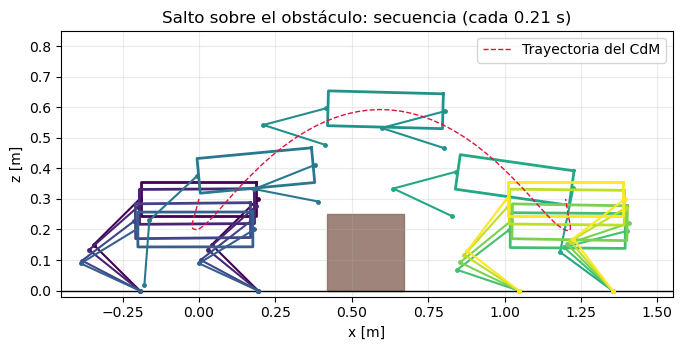

In [48]:
COL_F = ["#cfe8ff", "#ffe3c2", "#e6e6e6", "#ffe3c2", "#cfe8ff"]


def sombrear(ax):
    for j in range(NF):
        ax.axvspan(limites_fase[j], limites_fase[j + 1], color=COL_F[j], alpha=0.5, lw=0)


def dibujar_obstaculo_2d(ax):
    ax.add_patch(plt.Rectangle((OBS_X1, 0), OBS_X2 - OBS_X1, OBS_H, color="#8d6e63", alpha=0.85))
    ax.axhline(0, color="k", lw=1)


# Secuencia de cuadros (vista lateral)
fig, ax = plt.subplots(figsize=(11, 3.6))
dibujar_obstaculo_2d(ax)
t_cuadros = np.linspace(0, t_nodos[-1], 11)
for n, t in enumerate(t_cuadros):
    pts, _, x, Rb = cuerpo_completo(t)
    col = plt.get_cmap("viridis")(n / (len(t_cuadros) - 1))
    cuerpo = np.array([x[:3] + Rb @ np.array([sx * lx, 0, sz * lz])
                       for sx, sz in [(1, 1), (1, -1), (-1, -1), (-1, 1), (1, 1)]])
    ax.plot(cuerpo[:, 0], cuerpo[:, 2], color=col, lw=2)
    for i in (1, 3):                     # patas izquierdas (las derechas se superponen)
        ax.plot(pts[i, 1:, 0], pts[i, 1:, 2], "-o", color=col, lw=1.5, ms=2.5)
ax.plot(x_nodos[0], x_nodos[2], "--", color="crimson", lw=1, label="Trayectoria del CdM")
ax.set(xlabel="x [m]", ylabel="z [m]", title="Salto sobre el obstáculo: secuencia (cada %.2f s)" % t_cuadros[1])
ax.set_aspect("equal"); ax.set_xlim(-0.45, 1.55); ax.set_ylim(-0.02, 0.85); ax.legend(loc="upper right")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "p1_secuencia.png"), dpi=160); plt.show()

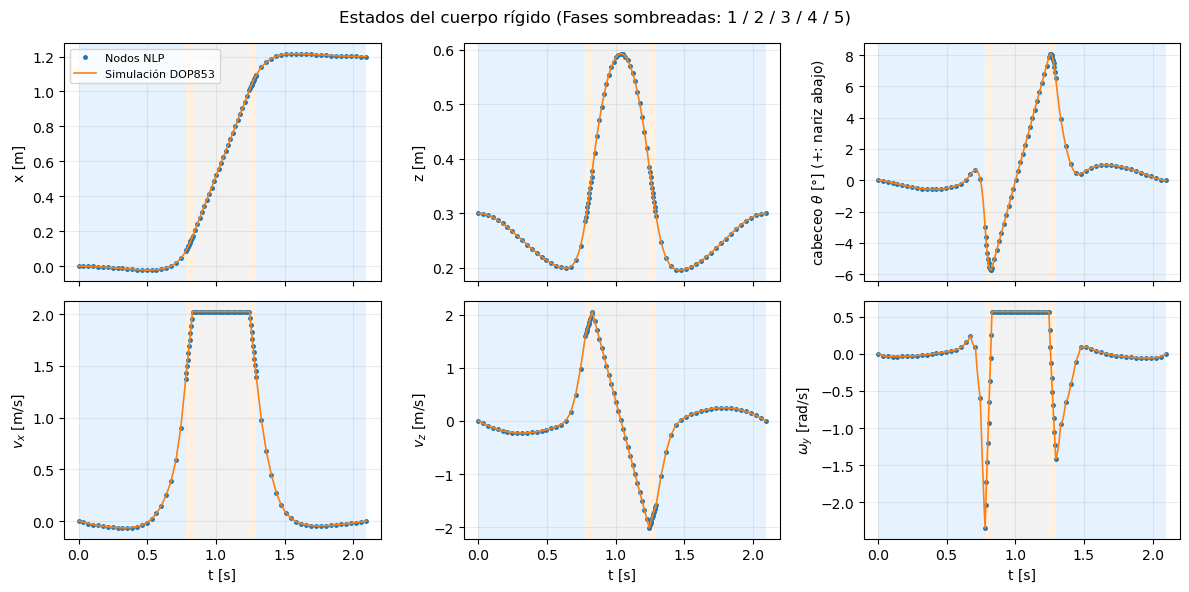

In [49]:
fig, axs = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
etiq = ["x [m]", "z [m]", "cabeceo $\\theta$ [°] (+: nariz abajo)", "$v_x$ [m/s]", "$v_z$ [m/s]", "$\\omega_y$ [rad/s]"]
for a, j, e in zip(axs.flat, [0, 2, 4, 6, 8, 10], etiq):
    sombrear(a)
    esc = 180 / np.pi if j == 4 else 1
    a.plot(t_nodos, esc * x_nodos[j], "o", ms=2.5, color="tab:blue", label="Nodos NLP")
    a.plot(t_sim, esc * x_sim[j], "-", color="tab:orange", lw=1.2, label="Simulación DOP853")
    a.set_ylabel(e)
for a in axs[1]:
    a.set_xlabel("t [s]")
axs[0, 0].legend(fontsize=8)
fig.suptitle("Estados del cuerpo rígido (Fases sombreadas: 1 / 2 / 3 / 4 / 5)")
fig.tight_layout(); fig.savefig(os.path.join(FIG, "p1_estados.png"), dpi=160); plt.show()

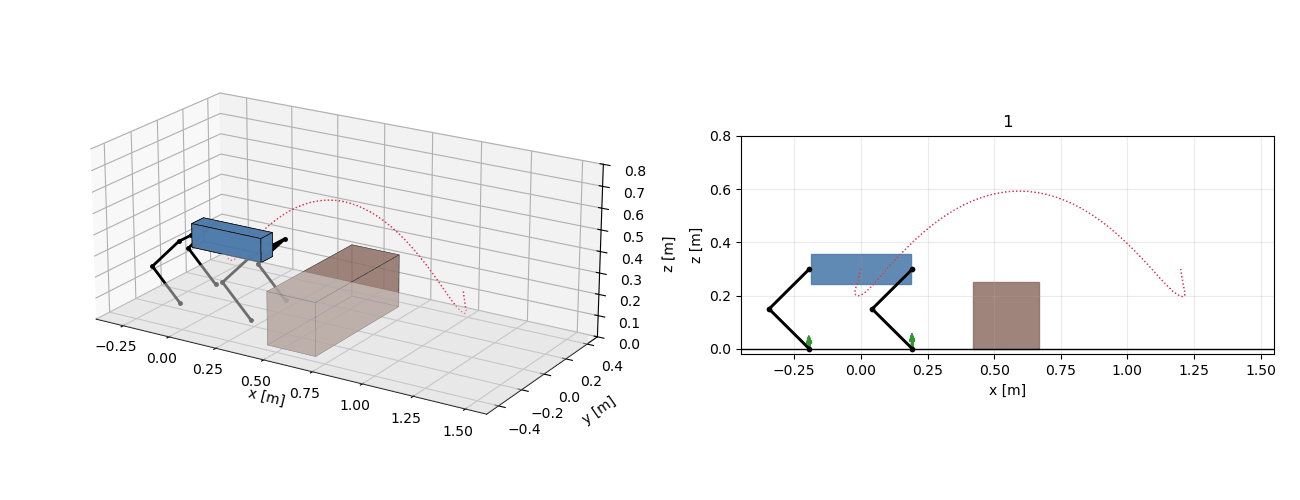

In [51]:
def caja(centro, dims, Rb=np.eye(3)):
    dx, dy, dz = np.asarray(dims) / 2
    v = np.array([[sx * dx, sy * dy, sz * dz] for sx in (-1, 1) for sy in (-1, 1) for sz in (-1, 1)])
    v = centro + v @ Rb.T
    caras = [[0, 1, 3, 2], [4, 5, 7, 6], [0, 1, 5, 4], [2, 3, 7, 6], [0, 2, 6, 4], [1, 3, 7, 5]]
    return [[v[j] for j in c] for c in caras]


fig = plt.figure(figsize=(13, 5))
ax3 = fig.add_axes([0.0, 0.0, 0.52, 1.0], projection="3d")
ax2 = fig.add_axes([0.57, 0.14, 0.41, 0.74])
suelo = [[[-0.4, -0.5, 0], [1.6, -0.5, 0], [1.6, 0.5, 0], [-0.4, 0.5, 0]]]
obs_caras = caja([(OBS_X1 + OBS_X2) / 2, 0, OBS_H / 2], [OBS_X2 - OBS_X1, 0.7, OBS_H])
fps = 30
t_anim = np.r_[np.linspace(0, t_nodos[-1], int(fps * t_nodos[-1]) + 1), np.full(15, t_nodos[-1])]


def dibujar(n):
    t = t_anim[n]
    pts, _, x, Rb = cuerpo_completo(t)
    ax3.cla(); ax2.cla()
    ax3.add_collection3d(Poly3DCollection(suelo, facecolor="#dddddd", alpha=0.5))
    ax3.add_collection3d(Poly3DCollection(obs_caras, facecolor="#8d6e63", alpha=0.6, edgecolor="k", lw=0.3))
    ax3.add_collection3d(Poly3DCollection(caja(x[:3], go2.CUERPO, Rb), facecolor="#4f7cac",
                                          alpha=0.9, edgecolor="k", lw=0.5))
    for i in range(4):
        ax3.plot(*pts[i].T, "-o", color="k", lw=2, ms=2.5)
    ax3.plot(x_nodos[0], x_nodos[1], x_nodos[2], ":", color="crimson", lw=1)
    ax3.set(xlim=(-0.4, 1.6), ylim=(-0.5, 0.5), zlim=(0, 0.8), xlabel="x [m]", ylabel="y [m]", zlabel="z [m]")
    ax3.set_box_aspect((2.0, 1.0, 0.8), zoom=1.05); ax3.view_init(elev=20, azim=-58)
    ax3.set_title(f"Go2 (SRBM + CI)   t = {t:.2f} s")
    dibujar_obstaculo_2d(ax2)
    cuerpo = np.array([x[:3] + Rb @ np.array([sx * lx, 0, sz * lz])
                       for sx, sz in [(1, 1), (1, -1), (-1, -1), (-1, 1), (1, 1)]])
    ax2.fill(cuerpo[:, 0], cuerpo[:, 2], color="#4f7cac", alpha=0.9)
    for i in range(4):
        ax2.plot(pts[i, 1:, 0], pts[i, 1:, 2], "-o", color="k" if i % 2 else "gray", lw=2, ms=3)
    ax2.plot(x_nodos[0], x_nodos[2], ":", color="crimson", lw=1)
    k = min(np.searchsorted(t_nodos, t, side="right") - 1, len(fase_nodo) - 1)
    fz = u_nodos[2::3, k]
    for i in range(4):
        if fz[i] > 1:
            pie = pts[i, -1]
            ax2.arrow(pie[0], pie[2], u_nodos[3 * i, k] / 600, fz[i] / 600, color="green",
                      width=0.006, length_includes_head=True)
    ax2.set(xlim=(-0.45, 1.55), ylim=(-0.02, 0.8), xlabel="x [m]", ylabel="z [m]",
            title=FASES[fase_nodo[k]]["nombre"])
    ax2.set_aspect("equal")
    return []


anim = FuncAnimation(fig, dibujar, frames=len(t_anim), interval=1000 / fps)
ruta_gif = os.path.join(FIG, "p1_salto.gif")
anim.save(ruta_gif, writer=PillowWriter(fps=fps))
plt.close(fig)
display(Image(filename=ruta_gif))